# Преамбула

Предложенный набор данных содержит данные 49 штатов США по состоянию на 1950 г.:
- **State**: название штата
- **Ocean**: близость к морю
- **Lat**: широта
- **Long**: долгота
- **Mort**: смертность от рака кожи (количество смертей на 10 млн. населения)

# Задание 1

Необходимо научиться предсказывать значение смертности от рака кожи по значению [широты](https://ru.wikipedia.org/wiki/Широта).

1.   Загрузить датасет по адресу https://online.stat.psu.edu/stat462/sites/onlinecourses.science.psu.edu.stat462/files/data/skincancer/index.txt (Подсказка: для корректного прочтения файла используйте в функции read_csv аргумент sep="\s+")
2.   Отобразить краткую информацию о датасете
3.   Построить график зависимости смертности от широты, подписать график и оси координат
4.   Обучить модель линейной регрессии и визуализировать на графике зависимости смертности от широты прямую, харатеризующую обученную модель линейной регрессии
5.   Предоставить возможность пользователю ввести в поле ввода значение широты и вывести предсказанное значение смертности








In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error
from dotenv import dotenv_values


config = dotenv_values(".env")


df = pd.read_csv('skincancer.txt', sep=r'\s+')

In [47]:
df.head()

,State,Lat,Mort,Ocean,Long
0,Alabama,33.0,219,1,87.0
1,Arizona,34.5,160,0,112.0
2,Arkansas,35.0,170,0,92.5
3,California,37.5,182,1,119.5
4,Colorado,39.0,149,0,105.5


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   State   49 non-null     object 
 1   Lat     49 non-null     float64
 2   Mort    49 non-null     int64  
 3   Ocean   49 non-null     int64  
 4   Long    49 non-null     float64
dtypes: float64(2), int64(2), object(1)
memory usage: 2.0+ KB


In [49]:
df.describe()

,Lat,Mort,Ocean,Long
count,49.000000,49.000000,49.000000,49.000000
mean,39.532653,152.877551,0.448980,90.936735
std,4.610874,33.428177,0.502545,14.866485
min,28.000000,86.000000,0.000000,69.000000
25%,36.000000,128.000000,0.000000,78.500000
50%,39.500000,147.000000,0.000000,89.500000
75%,43.000000,178.000000,1.000000,100.000000
max,47.500000,229.000000,1.000000,121.000000


In [50]:
# 4. Обучение модели линейной регрессии
X = df[['Lat']].to_numpy()
y = df['Mort'].to_numpy()

regression_model = LinearRegression()
regression_model.fit(X, y)
y_pred = regression_model.predict(X)
theta_0 = regression_model.intercept_
theta_1 = regression_model.coef_[0]

print(f"Уравнение регрессии: Mort = {theta_0:.2f} + ({theta_1:.2f}) * Lat\n")

# Расчет метрик 
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)
rmse = root_mean_squared_error(y, y_pred)
mae = mean_absolute_error(y, y_pred)

print(f"R^2 = {r2:.4f}")
print(f"MSE = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"MAE = {mae:.4f}")


Уравнение регрессии: Mort = 389.19 + (-5.98) * Lat

R^2 = 0.6798
MSE = 350.4707
RMSE = 18.7209
MAE = 15.5384


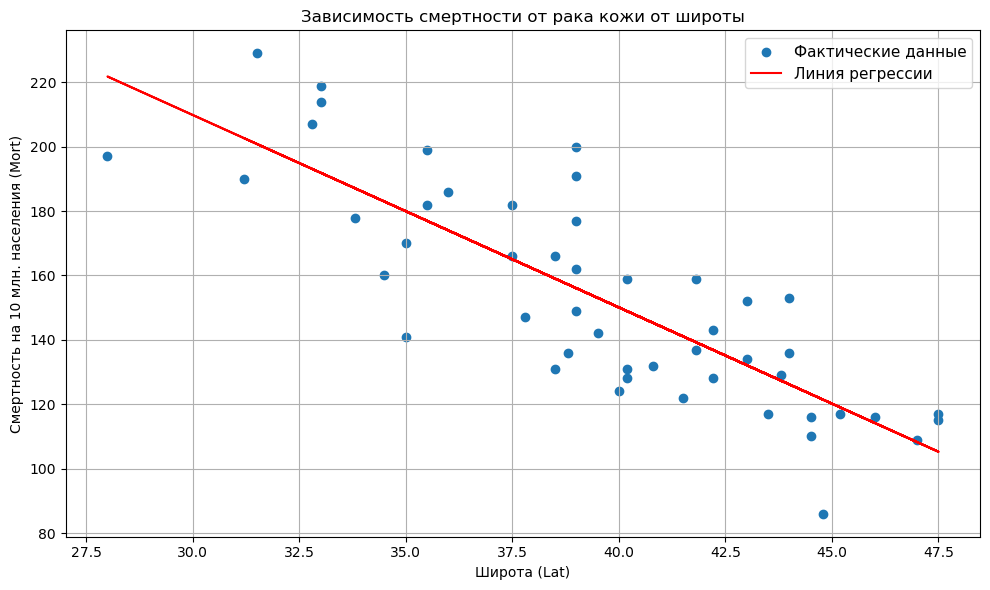

In [51]:
# 3. Построение графика

plt.figure(figsize=(10, 6))
plt.scatter(df['Lat'], df['Mort'], label='Фактические данные')
plt.plot(df['Lat'], y_pred, color='red', label='Линия регрессии')

plt.title('Зависимость смертности от рака кожи от широты')
plt.xlabel('Широта (Lat)')
plt.ylabel('Смертность на 10 млн. населения (Mort)')
plt.grid(True)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [52]:
try:
    user_lat_input = input("Введите значение широты: ").strip()
    if not user_lat_input:
        user_lat = 40
        print(f"Использовано значение по умолчанию: {user_lat}")
    else:
        user_lat = float(user_lat_input.replace(',', '.'))
    
    predicted_mort = regression_model.predict([[user_lat]])[0]
    print(f"Для широты {user_lat}° с.ш.:")
    print(f"Предсказанное значение смертности: {predicted_mort:.2f} чел. на 10 млн. населения")
except ValueError:
    print("Ошибка: введено некорректное значение")

Для широты 38.0° с.ш.:
Предсказанное значение смертности: 162.04 чел. на 10 млн. населения


# Задание 2

Необходимо разработать программу, работающую по следующему алгоритму:
1. Запросить у пользователя адрес в США (без указания страны)
2. Получить при помощи функции get_geo_object географический объект по указанному адресу, извлечь из него данные широты
3. Использовать данные широты чтобы предсказать возможную смертность. Вывести на экран итоговое сообщение (см. пример).Смертность округлить до целых.

**Пример**:

Ввод пользователя:
```
2661 Brown St, Napa, CA 94558
```
Итоговое сообщение:
```
Адрес: Brown Street, Napa, Napa County, California, 94558, United States  
Предсказанная смертность: 160 чел. на 10 млн. чел.
```

In [53]:
import requests
import json
from dotenv import dotenv_values

config = dotenv_values(".env")

def get_geo_object(query_string: str):
    """
    Находит географический объект по адресу через API geocode.maps.co.

    Аргументы
    ----------
    query_string : str
        Строка адреса в свободном формате.

    Возвращает
    ----------
    safe_url : str
        Сформированная строка запроса со скрытым API-ключом
    data : list[dict]
        Список словарей географических объектов
    """
    geo_url = "https://geocode.maps.co/search"
    
    params = {
        "q": query_string,
        "api_key": config["API_KEY"]
    }
    
    response = requests.get(geo_url, params=params, timeout=10)
    response.raise_for_status()
        
    return response.url, response.json()

query = "1001 Van Ness Ave, San Francisco, CA 94109"
url, response = get_geo_object(query)

print(f"Request URL: {url}")
print(json.dumps(response, indent=2, ensure_ascii=False))


Request URL: https://geocode.maps.co/search?q=1001+Van+Ness+Ave%2C+San+Francisco%2C+CA+94109&api_key=6ad1029cd0865387779506bwi5ef31f
[
  {
    "place_id": 375096689,
    "licence": "Data © OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright",
    "osm_type": "way",
    "osm_id": 766798668,
    "lat": "37.7853683",
    "lon": "-122.4211324",
    "class": "place",
    "type": "house",
    "place_rank": 30,
    "importance": 9.99999999995449e-06,
    "addresstype": "place",
    "name": "",
    "display_name": "1001, Van Ness Avenue, Civic Center, San Francisco, California, 94109, United States",
    "address": {
      "house_number": "1001",
      "road": "Van Ness Avenue",
      "quarter": "Civic Center",
      "city": "San Francisco",
      "state": "California",
      "ISO3166-2-lvl4": "US-CA",
      "postcode": "94109",
      "country": "United States",
      "country_code": "us"
    },
    "extratags": null,
    "namedetails": null,
    "boundingbox": [
      "37.7853183",

In [54]:
# 1. Запрос адреса у пользователя
user_address = input("Введите адрес в США: ").strip()
if not user_address:
    user_address = "1001 Van Ness Ave, San Francisco, CA 94109"
    print(f"Используется тестовый адрес по умолчанию из примера: {user_address}")

# 2. Получение географического объектаё
request_url, geo_results = get_geo_object(user_address)

if geo_results and isinstance(geo_results, list) and len(geo_results) > 0:
    geo_obj = geo_results[0]
    display_name = geo_obj.get("display_name", user_address)
    lat = float(geo_obj["lat"])

    # 3. Предсказание возможной смертности
    mort_pred = regression_model.predict([[lat]])[0]
    mort_rounded = round(mort_pred)

    # Вывод итогового сообщения
    print(f"\nАдрес: {display_name}")
    print(f"Предсказанная смертность: {mort_rounded} чел. на 10 млн. чел.")
else:
    print(f"Ошибка: не удалось найти географический объект по адресу '{user_address}'")

# примеры ввода:
# 4821 Ridge Top Cir
# 1408 Mockingbird Ln

Используется тестовый адрес по умолчанию из примера: 1001 Van Ness Ave, San Francisco, CA 94109

Адрес: 1001, Van Ness Avenue, Civic Center, San Francisco, California, 94109, United States
Предсказанная смертность: 163 чел. на 10 млн. чел.


# Контрольные вопросы

## Вопрос 1:
Приведите примеры (2-3) проблем, которые могут быть решены при помощи регрессии?

## Ответ 1:
1. Прогнозирование пассажиропотока новой станции метро
- Городу нужно оценить, сколько людей будет ежедневно пользоваться еще не построенной станцией, чтобы рассчитать нагрузку на составы и вестибюли.
- Факторы: плотность населения в радиусе километра, количество офисных и жилых зданий, наличие наземного транспорта и удаленность от центра.
2. Оценка рыночной стоимости квартиры в новостройке
- Застройщику или банку нужно справедливо оценить стоимость еще строящегося жилья или выставить цену на квартиры в новом доме.
- Факторы: площадь квартиры, этажность, удаленность от метро, количество комнат и класс отделки.
3. Прогнозирование суточного потребления электроэнергии в городе
- Энергосбытовым компаниям необходимо заранее планировать объемы генерации энергии, чтобы не было дефицита или избытка.
- Факторы: метеорологические данные (прогноза температуры воздуха, скорости ветра), день недели (рабочий или выходной) и время суток.

## Вопрос 2:
Сколько параметров в уравнении линейной регрессии? Опишите их смысл.

## Ответ 2:
В простой линейной регрессии два параметра: свободный член задает базовое значение целевой переменной при нулевом признаке, а угловой коэффициент показывает, насколько изменяется результат при увеличении признака на единицу. Если признаков несколько, то параметров будет на один больше числа признаков: один свободный член и по одному весовому коэффициенту на каждый фактор.

## Вопрос 3:
Для чего применяются библиотеки requests и re?


## Ответ 3:
Библиотека requests нужна для отправки сетевых HTTP-запросов и получения данных от внешних веб-сервисов и API, а модуль re используется для работы с регулярными выражениями, например чтобы очистить и отформатировать строку адреса перед передачей в поисковый запрос.

# ИЛИ

Взять один из датасетов из предыдущих работ и обучить для данной задачи модель.
Вы должны провести нормализацию и стандартизацию. Выбрать целевой признак Y. Выбрать признаки для обучения Х. Обучить модель. Сделать ввод признаков в нормальном виде (программа), дать ответ